# CÂU 6 – PHÂN TÍCH DISCOUNT TRONG E-COMMERCE

**Mục tiêu:** phân tích mối liên hệ giữa `discount_pct` với số lượng sản phẩm (`quantity`) và giá trị giao dịch (`total_amount_usd`).

Notebook gồm: đọc dữ liệu, làm sạch, chia nhóm Discount, thống kê mô tả, kiểm định Spearman và Kruskal–Wallis, vẽ Box Plot và xuất kết quả.

**Cách dùng:** đặt notebook trong thư mục `notebooks/` của dự án `Ecommerce_analysis`. Dataset cần có ở `data/cleaned/orders_cleaned.csv`.

## 1. Import thư viện
Nếu thiếu thư viện, bỏ dấu `#` ở dòng pip install rồi chạy cell.

In [1]:
# Cài thư viện bằng: pip install -r requirements.txt (ở thư mục gốc dự án)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


In [2]:
print("Thư mục hiện tại:", Path.cwd())
print("Có thư mục data/cleaned không:",
      (Path.cwd().parent / "data" / "cleaned").exists())

Thư mục hiện tại: /home/claude/work/final/notebooks
Có thư mục data/cleaned không: True


## 2. Tìm và đọc dữ liệu

In [3]:
DATA_RELATIVE = Path("data") / "cleaned" / "orders_cleaned.csv"
MARTS_DIR = Path("..") / "data" / "marts"  # bảng CSV và nhận xét
PNG_DIR = Path("..") / "exports" / "archive_static_png"  # biểu đồ PNG
HTML_DIR = Path("..") / "exports" / "interactive_html"  # biểu đồ Plotly tương tác

search_dirs = [Path.cwd(), *Path.cwd().parents]
DATA_FILE = next(
    (folder / DATA_RELATIVE for folder in search_dirs
     if (folder / DATA_RELATIVE).exists()),
    None
)

if DATA_FILE is None:
    raise FileNotFoundError(
        "Không tìm thấy data/cleaned/orders_cleaned.csv. "
        "Hãy đặt notebook trong thư mục notebooks/ của dự án Ecommerce_analysis."
    )

print("Dataset:", DATA_FILE.resolve())
df_raw = pd.read_csv(DATA_FILE)
print("Kích thước dữ liệu:", df_raw.shape)
display(df_raw.head())


Dataset: /home/claude/work/final/data/cleaned/orders_cleaned.csv
Kích thước dữ liệu: (25000, 29)


,order_id,customer_id,order_date,year,month,quarter,day_of_week,product_name,category,unit_price_usd,quantity,subtotal_usd,discount_pct,discount_amount_usd,shipping_fee_usd,tax_pct,tax_amount_usd,total_amount_usd,payment_method,device_used,delivery_days,delivery_date,order_status,returned,customer_rating,session_duration_minutes,pages_viewed_before_purchase,is_repeat_customer,rating_provided
0,O000001,C07108,2020-08-27,2020,8,Q3,Thursday,Tire Inflator,Automotive,62.91,1,62.91,0,0.00,0.00,18,11.32,74.23,Credit Card,Desktop,3,2020-08-30,Delivered,0,NaN,14.40,1,1,0
1,O000002,C03487,2024-04-11,2024,4,Q2,Thursday,Stud Earrings Gold,Jewelry & Accessories,18.44,1,18.44,0,0.00,3.99,10,1.84,24.27,Credit Card,Mobile,2,2024-04-13,Delivered,0,NaN,9.00,4,0,0
2,O000003,C03062,2023-06-25,2023,6,Q2,Sunday,Pen Set Premium,Office Supplies,109.79,1,109.79,20,21.96,0.00,8,7.03,94.86,PayPal,Desktop,3,2023-06-28,Delivered,0,4.00,3.20,17,0,1
3,O000004,C00888,2020-08-16,2020,8,Q3,Sunday,Smart Watch Series 5,Electronics,87.21,1,87.21,50,43.60,0.00,8,3.49,47.10,Credit Card,Tablet,2,2020-08-18,Returned,1,NaN,32.20,3,1,0
4,O000005,C01674,2020-04-24,2020,4,Q2,Friday,Stud Earrings Gold,Jewelry & Accessories,94.30,2,188.60,0,0.00,9.99,5,9.43,208.02,Debit Card,Mobile,5,2020-04-29,Delivered,0,2.80,54.70,2,1,1


## 3. Kiểm tra các cột cần thiết
Ba cột theo notebook phân tích hiện tại là `discount_pct`, `quantity`, `total_amount_usd`.

In [4]:
required = ["discount_pct", "quantity", "total_amount_usd"]
missing = [c for c in required if c not in df_raw.columns]
if missing:
    raise ValueError(f"Dataset thiếu cột: {missing}")

display(df_raw[required].head())
display(df_raw[required].describe())
print("Giá trị thiếu:")
display(df_raw[required].isna().sum())


,discount_pct,quantity,total_amount_usd
0,0,1,74.23
1,0,1,24.27
2,20,1,94.86
3,50,1,47.10
4,0,2,208.02


,discount_pct,quantity,total_amount_usd
count,"25,000.00","25,000.00","25,000.00"
mean,5.63,1.70,125.46
std,9.74,1.05,145.64
min,0.00,1.00,3.00
25%,0.00,1.00,43.45
50%,0.00,1.00,78.78
75%,10.00,2.00,149.87
max,50.00,5.00,"2,730.88"


Giá trị thiếu:


discount_pct        0
quantity            0
total_amount_usd    0
dtype: int64

## 4. Làm sạch dữ liệu
Chuyển cột về kiểu số, loại dòng thiếu dữ liệu và giá trị không hợp lệ. Discount nằm trong khoảng 0–100; Quantity và Amount không âm.

In [5]:
df = df_raw.copy()
for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

n_before = len(df)
df = df.dropna(subset=required).copy()
df = df[
    df["discount_pct"].between(0, 100)
    & (df["quantity"] >= 0)
    & (df["total_amount_usd"] >= 0)
].copy()

print(f"Số dòng ban đầu: {n_before:,}")
print(f"Số dòng hợp lệ: {len(df):,}")
print(f"Số dòng bị loại: {n_before - len(df):,}")
if df.empty:
    raise ValueError("Không còn dòng dữ liệu hợp lệ.")


Số dòng ban đầu: 25,000
Số dòng hợp lệ: 25,000
Số dòng bị loại: 0


## 5. Chia Discount thành 5 nhóm
Nhóm 0%, 1–10%, 11–20%, 21–30% và trên 30%.

In [6]:
discount_bins = [-0.001, 0, 10, 20, 30, 100]
discount_labels = [
    "0% (Không giảm)", "1–10%", "11–20%", "21–30%", "Trên 30%"
]

df["discount_group"] = pd.cut(
    df["discount_pct"],
    bins=discount_bins,
    labels=discount_labels,
    include_lowest=True,
    right=True
)

display(
    df["discount_group"]
    .value_counts(sort=False, dropna=False)
    .rename("Số giao dịch")
    .to_frame()
)


,Số giao dịch
discount_group,
0% (Không giảm),16239
1–10%,3915
11–20%,3069
21–30%,1213
Trên 30%,564


## 6. Thống kê mô tả theo nhóm Discount

In [7]:
summary = (
    df.groupby("discount_group", observed=False)
    .agg(
        so_giao_dich=("quantity", "size"),
        quantity_trung_binh=("quantity", "mean"),
        quantity_trung_vi=("quantity", "median"),
        amount_trung_binh=("total_amount_usd", "mean"),
        amount_trung_vi=("total_amount_usd", "median"),
        tong_amount=("total_amount_usd", "sum"),
        discount_trung_binh=("discount_pct", "mean")
    )
)
summary["ty_trong_giao_dich_pct"] = (
    summary["so_giao_dich"] / summary["so_giao_dich"].sum() * 100
)
summary = summary.round(2)
display(summary)


,so_giao_dich,quantity_trung_binh,quantity_trung_vi,amount_trung_binh,amount_trung_vi,tong_amount,discount_trung_binh,ty_trong_giao_dich_pct
discount_group,,,,,,,,
0% (Không giảm),16239,1.70,1.00,133.10,83.79,"2,161,393.86",0.00,64.96
1–10%,3915,1.69,1.00,125.10,78.73,"489,749.78",7.82,15.66
11–20%,3069,1.70,1.00,108.41,71.12,"332,701.56",17.15,12.28
21–30%,1213,1.65,1.00,92.86,61.33,"112,641.10",27.28,4.85
Trên 30%,564,1.70,1.00,70.78,45.31,"39,918.36",43.28,2.26


## 7. Kiểm định tương quan Spearman

Spearman đo chiều hướng và mức độ liên hệ đơn điệu:
- rho dương: hai biến có xu hướng cùng chiều.
- rho âm: hai biến có xu hướng ngược chiều.
- rho gần 0: liên hệ đơn điệu yếu.

Dùng p-value với mức ý nghĩa 0.05. Tương quan không chứng minh quan hệ nhân quả.

In [8]:
spearman_quantity = stats.spearmanr(df["discount_pct"], df["quantity"])
spearman_amount = stats.spearmanr(df["discount_pct"], df["total_amount_usd"])

spearman_results = pd.DataFrame([
    {"Cặp biến": "Discount – Quantity",
     "Spearman rho": spearman_quantity.statistic,
     "p-value": spearman_quantity.pvalue},
    {"Cặp biến": "Discount – Amount",
     "Spearman rho": spearman_amount.statistic,
     "p-value": spearman_amount.pvalue}
])
display(spearman_results.round(6))


,Cặp biến,Spearman rho,p-value
0,Discount – Quantity,-0.01,0.19
1,Discount – Amount,-0.11,0.00


## 8. Kiểm định Kruskal–Wallis

Kiểm tra phân bố Quantity và Amount có khác biệt giữa các nhóm Discount hay không. Nếu p < 0.05, có bằng chứng rằng ít nhất một nhóm khác biệt; kiểm định này không cho biết cụ thể nhóm nào khác nhóm nào.

In [9]:
quantity_groups = [
    g["quantity"].to_numpy()
    for _, g in df.groupby("discount_group", observed=True) if len(g)
]
amount_groups = [
    g["total_amount_usd"].to_numpy()
    for _, g in df.groupby("discount_group", observed=True) if len(g)
]

kw_quantity = stats.kruskal(*quantity_groups) if len(quantity_groups) >= 2 else None
kw_amount = stats.kruskal(*amount_groups) if len(amount_groups) >= 2 else None

kruskal_results = pd.DataFrame([
    {"Biến": "Quantity", "H statistic": kw_quantity.statistic if kw_quantity else np.nan,
     "p-value": kw_quantity.pvalue if kw_quantity else np.nan},
    {"Biến": "Amount", "H statistic": kw_amount.statistic if kw_amount else np.nan,
     "p-value": kw_amount.pvalue if kw_amount else np.nan}
])
display(kruskal_results.round(6))


,Biến,H statistic,p-value
0,Quantity,2.62,0.62
1,Amount,392.49,0.00


## 9. Box Plot – Discount và Quantity
Đường giữa hộp là trung vị; mép hộp là Q1 và Q3; các điểm ngoài râu thường được xem là ngoại lệ.

In [10]:
fig_quantity = px.box(
    df, x="discount_group", y="quantity",
    category_orders={"discount_group": discount_labels},
    points="outliers",
    title="Phân bố số lượng sản phẩm theo nhóm Discount",
    labels={"discount_group": "Nhóm chiết khấu", "quantity": "Số lượng sản phẩm"}
)
fig_quantity.update_layout(showlegend=False, template="plotly_white")
from IPython.display import display
display(fig_quantity)


![Box Plot Discount và Quantity](../exports/archive_static_png/boxplot_quantity.png)

## 10. Box Plot – Discount và Amount

In [11]:
fig_amount = px.box(
    df, x="discount_group", y="total_amount_usd",
    category_orders={"discount_group": discount_labels},
    points="outliers",
    title="Phân bố giá trị giao dịch theo nhóm Discount",
    labels={"discount_group": "Nhóm chiết khấu",
            "total_amount_usd": "Giá trị giao dịch (USD)"}
)
fig_amount.update_layout(showlegend=False, template="plotly_white")
display(fig_amount)


![Box Plot Discount và Amount](../exports/archive_static_png/boxplot_amount.png)

## 11. Nhận xét tự động từ kết quả thực tế
Không kết luận quan hệ nhân quả chỉ từ tương quan hoặc kiểm định.

In [12]:
def spearman_comment(name, result):
    rho, p = result.statistic, result.pvalue
    direction = "cùng chiều" if rho > 0 else "ngược chiều" if rho < 0 else "không thể hiện chiều hướng"
    significance = "có ý nghĩa thống kê" if p < 0.05 else "chưa có ý nghĩa thống kê"
    return f"{name}: rho={rho:.4f}, p={p:.6g}; xu hướng {direction}, {significance}."

print(spearman_comment("Discount – Quantity", spearman_quantity))
print(spearman_comment("Discount – Amount", spearman_amount))

for name, result in [("Quantity", kw_quantity), ("Amount", kw_amount)]:
    if result is not None:
        conclusion = "có khác biệt phân bố giữa ít nhất hai nhóm" if result.pvalue < 0.05 else "chưa có bằng chứng khác biệt phân bố giữa các nhóm"
        print(f"Kruskal–Wallis {name}: H={result.statistic:.4f}, p={result.pvalue:.6g}; {conclusion}.")

print("Lưu ý: kết quả thể hiện mối liên hệ/khác biệt, không tự chứng minh Discount là nguyên nhân.")


Discount – Quantity: rho=-0.0083, p=0.190637; xu hướng ngược chiều, chưa có ý nghĩa thống kê.
Discount – Amount: rho=-0.1057, p=4.74429e-63; xu hướng ngược chiều, có ý nghĩa thống kê.
Kruskal–Wallis Quantity: H=2.6236, p=0.622647; chưa có bằng chứng khác biệt phân bố giữa các nhóm.
Kruskal–Wallis Amount: H=392.4901, p=1.16643e-83; có khác biệt phân bố giữa ít nhất hai nhóm.
Lưu ý: kết quả thể hiện mối liên hệ/khác biệt, không tự chứng minh Discount là nguyên nhân.


## 12. Lưu bảng, biểu đồ và nhận xét
Bảng CSV và nhận xét được lưu vào `data/marts/`, PNG vào `exports/archive_static_png/`, HTML (biểu đồ Plotly tương tác) vào `exports/interactive_html/`. PNG dùng để xem trực tiếp trên GitHub.

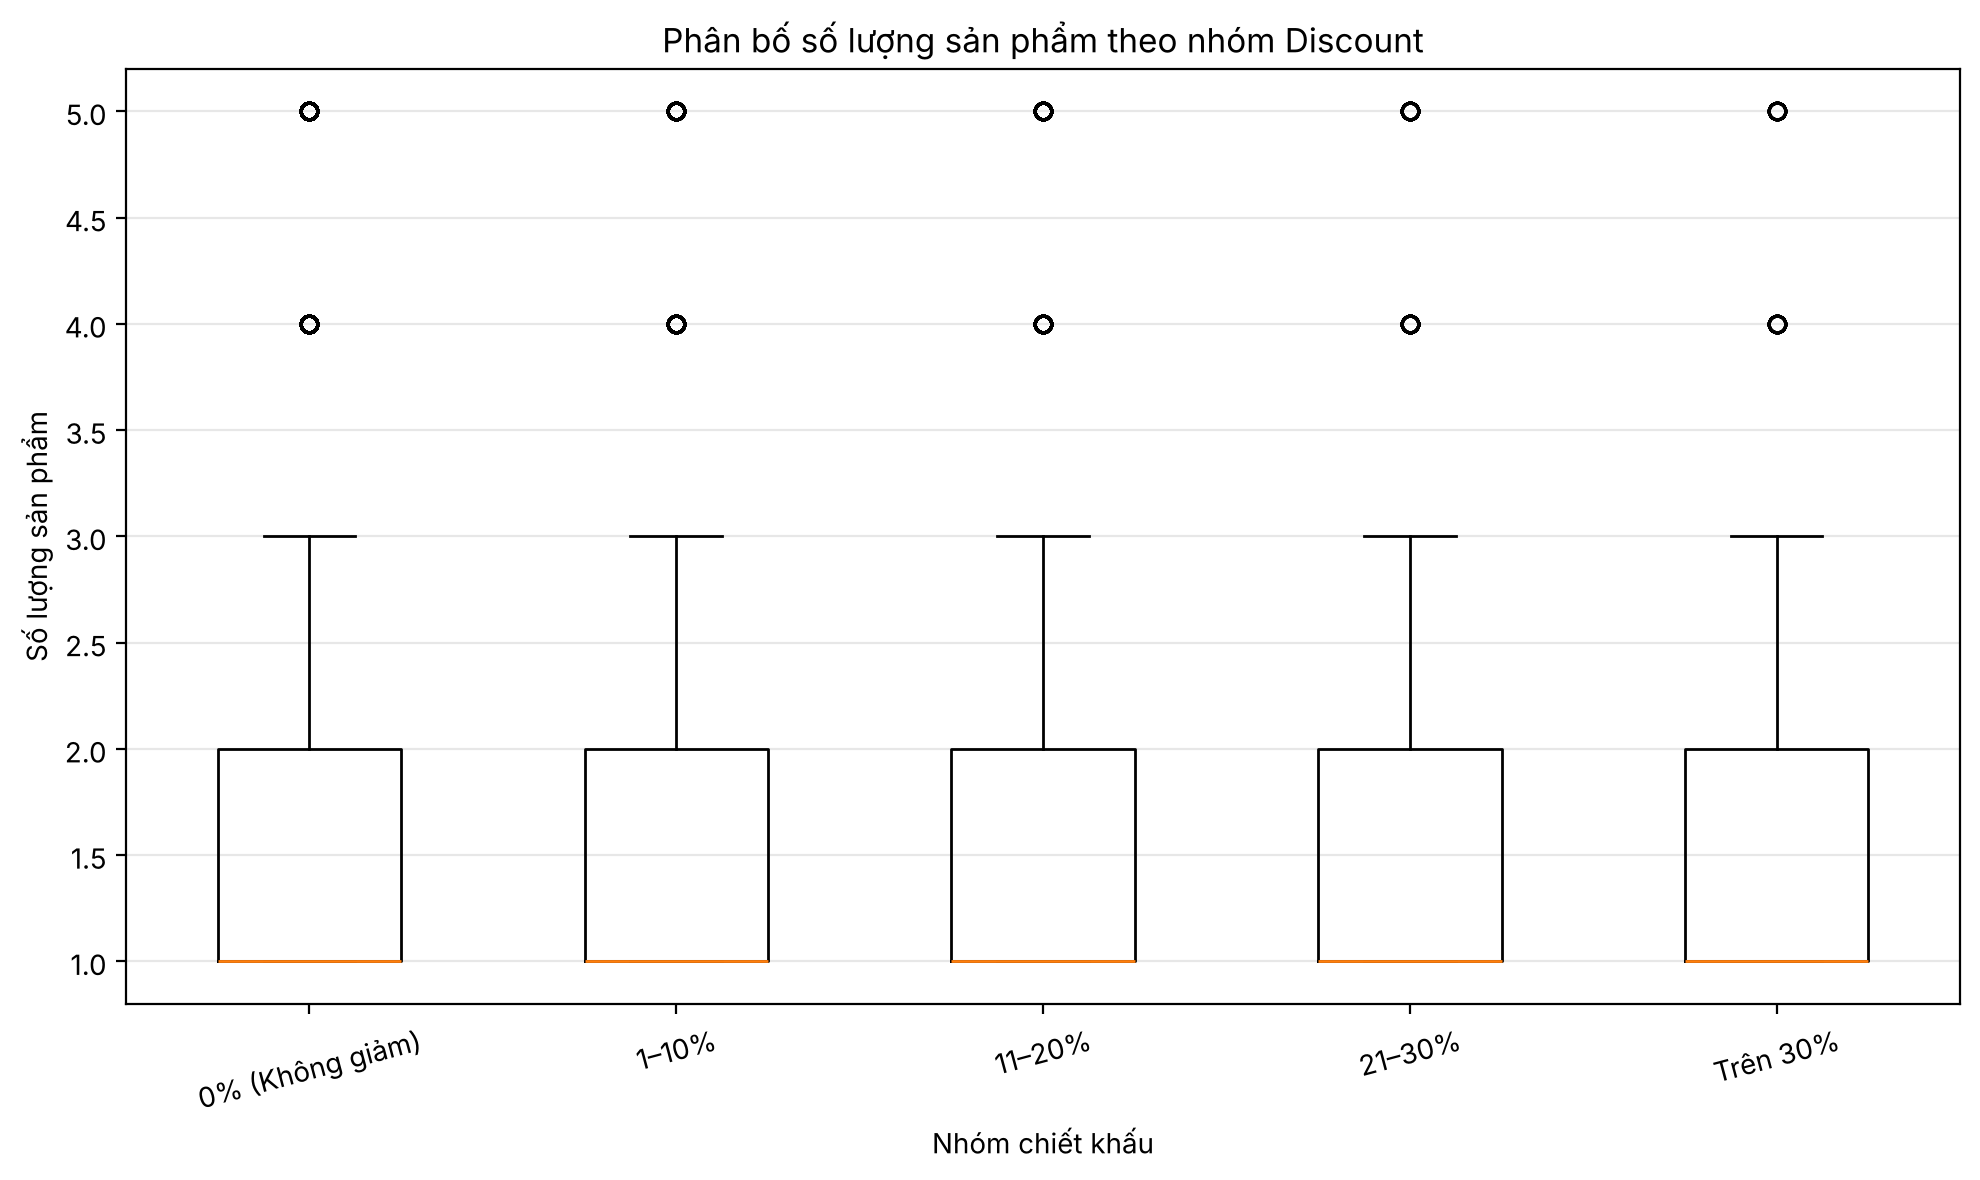

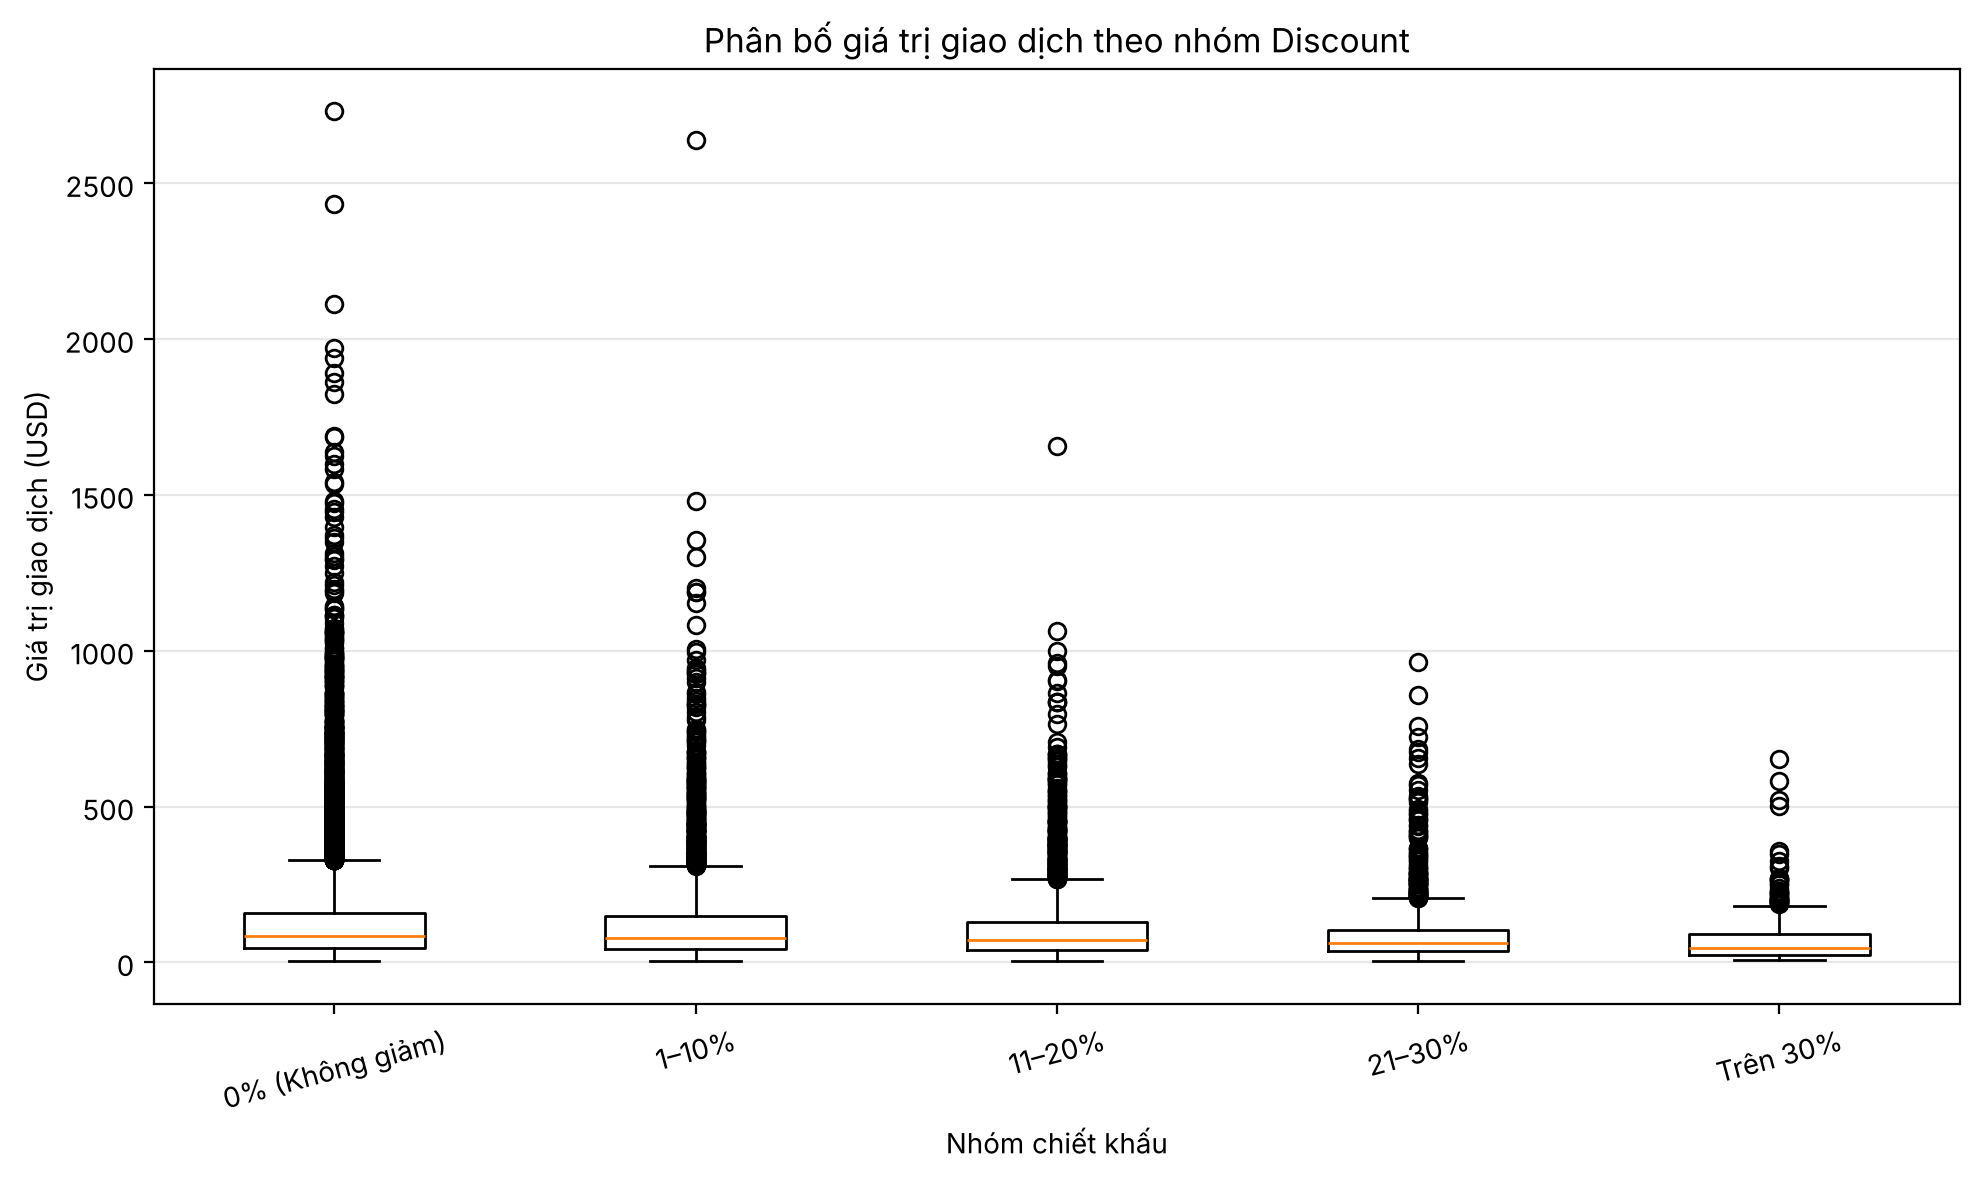

Đã lưu kết quả tại: /home/claude/work/final/data/marts | /home/claude/work/final/exports/archive_static_png | /home/claude/work/final/exports/interactive_html
Các file: ['boxplot_amount.html', 'boxplot_amount.png', 'boxplot_quantity.html', 'boxplot_quantity.png', 'cau6_nhan_xet.txt', 'discount_summary.csv']


In [13]:
MARTS_DIR.mkdir(parents=True, exist_ok=True)
PNG_DIR.mkdir(parents=True, exist_ok=True)
HTML_DIR.mkdir(parents=True, exist_ok=True)

summary.to_csv(MARTS_DIR / "discount_summary.csv", encoding="utf-8-sig")
fig_quantity.write_html(HTML_DIR / "boxplot_quantity.html")
fig_amount.write_html(HTML_DIR / "boxplot_amount.html")

# Lưu PNG bằng Matplotlib
fig, ax = plt.subplots(figsize=(10, 6))
q_data = [df.loc[df["discount_group"] == label, "quantity"].dropna()
          for label in discount_labels]
ax.boxplot(q_data, tick_labels=discount_labels, showfliers=True)
ax.set_title("Phân bố số lượng sản phẩm theo nhóm Discount")
ax.set_xlabel("Nhóm chiết khấu")
ax.set_ylabel("Số lượng sản phẩm")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
fig.tight_layout()
fig.savefig(PNG_DIR / "boxplot_quantity.png", dpi=180)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 6))
a_data = [df.loc[df["discount_group"] == label, "total_amount_usd"].dropna()
          for label in discount_labels]
ax.boxplot(a_data, tick_labels=discount_labels, showfliers=True)
ax.set_title("Phân bố giá trị giao dịch theo nhóm Discount")
ax.set_xlabel("Nhóm chiết khấu")
ax.set_ylabel("Giá trị giao dịch (USD)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
fig.tight_layout()
fig.savefig(PNG_DIR / "boxplot_amount.png", dpi=180)
plt.show()
plt.close(fig)

report = [
    "KET QUA PHAN TICH CAU 6 - DISCOUNT",
    f"Tong so giao dich hop le: {len(df):,}",
    spearman_comment("Discount va Quantity", spearman_quantity),
    spearman_comment("Discount va Amount", spearman_amount),
    f"Kruskal-Wallis Quantity: H={kw_quantity.statistic:.4f}, p={kw_quantity.pvalue:.6g}" if kw_quantity else "Kruskal-Wallis Quantity: khong du nhom",
    f"Kruskal-Wallis Amount: H={kw_amount.statistic:.4f}, p={kw_amount.pvalue:.6g}" if kw_amount else "Kruskal-Wallis Amount: khong du nhom",
    "Luu y: ket qua khong tu dong chung minh quan he nhan qua."
]
(MARTS_DIR / "cau6_nhan_xet.txt").write_text("\n".join(report), encoding="utf-8")

print("Đã lưu kết quả tại:", MARTS_DIR.resolve(), "|", PNG_DIR.resolve(), "|", HTML_DIR.resolve())
print("Các file:", sorted(p.name for d in (MARTS_DIR, PNG_DIR, HTML_DIR) for p in d.iterdir()
                          if p.name.startswith(("discount_summary", "boxplot_", "cau6_"))))
